# Bio-ORACLE Cleaning and Validation

- **Project:** OCEAVERA
- **Branch:** `pipeline/data-cleaning-bio-oracle`
- **Review date:** 12 October 2026

## Contributors

| Registration Number | Member Name | GitHub Account |
| --- | --- | --- |
| IT24100184 | Ushan Srinuka | `Ushan-Srinuka` |

This notebook records branch work; it is not an individual contribution statement or assessed reflection.

## 1. Purpose and scope

This notebook records the Bio-ORACLE intake, validation and scientific sign-off completed on this branch. It documents the OBIS-style raw-to-interim workflow and checks the saved results; it does not rerun the 356-product scan.

**Included:** provenance checks, NetCDF structure and value scans, grid/time checks, duplicate diagnostics and one current interim dataset.

**Not included:** changing raster values, filling missing cells, assigning land/water meaning, selecting predictors, extracting values, joining OBIS or modelling.

## 2. Work completed in this branch

1. **Raw staging:** Added [06_stage_bio_oracle_layers.py](../../src/data_preparation/06_stage_bio_oracle_layers.py). It checks the catalogue run and receipts, then copies the NetCDF payloads unchanged with checksum verification. Raw files remain intact. Its staging output is `data/interim/bio_oracle/source_validation/`.
2. **Array validation:** Added [07_clean_bio_oracle_layers.py](../../src/data_preparation/07_clean_bio_oracle_layers.py). It scans interim NetCDF structure, metadata, values, coordinates, time axes, grid consistency and duplicate patterns. It writes the cleaning manifest and summary without rewriting NetCDF values.
3. **Dataset retained in interim:** The cleaner scans the staged products and promotes the same directory to `data/interim/bio_oracle/cleaning/` after a successful scan. It contains **356 NetCDF products** under `<dataset-id>/`, plus `manifest.json` and `cleaning_summary.json`. Promotion is a same-volume directory rename; it does not create a second 3.7 GiB copy.
4. **Scientific sign-off:** The [cleaning record](../../docs/records/2026-10-11-bio-oracle-cleaning.md) documents the targeted review. The one KdPAR fill value stays missing, and `landmass` remains an empirical domain with unresolved land/water meaning.

### Scan results

| Measure | Result |
| --- | --- |
| Products | 356 readable: 55 baseline, 300 future-scenario, 1 terrain |
| Variables | 2,392 instances across 139 names |
| Grid and time | 178 × 165 grid; baseline 2000/2010; future labels 2020–2090 |
| Values scanned | 501,815,820; 83,181,580 declared fills; no NaN, infinity or declared range violations |
| Disposition | 355 validated; 1 review required; 0 modified or excluded |

## 3. How to read the data flow

| Part | What it does | Where it stands |
| --- | --- | --- |
| Stage script | Verifies the raw run and receipts; publishes unchanged NetCDF copies with provenance. | Produces the `source_validation/` stage when run. |
| Cleaning scan | Reads each staged NetCDF, checks source/interim hashes and records findings. | On success, renames the stage to `cleaning/`; does not rewrite payloads or create another copy. |
| Current interim dataset | Holds the retained products and cleaning reports. | `cleaning/<dataset-id>/` has 356 NetCDF files; this is the only active interim stage. |

Run the scripts in order: `python src/data_preparation/06_stage_bio_oracle_layers.py --run-manifest <raw-run-manifest>` then `python src/data_preparation/07_clean_bio_oracle_layers.py`. The first command stages the 356 products. The second scans those staged files, keeps detailed per-product diagnostics on a temporary spool to bound RAM, then promotes the stage to `cleaning/` without a second dataset copy.

## 4. Read-only verification

Run these cells from the repository root or one of its subfolders. They make no network requests and write no dataset files.

### Load the current reports

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

cwd = Path.cwd().resolve()
ROOT = next(
    (
        folder
        for folder in (cwd, *cwd.parents)
        if (folder / "data" / "interim" / "bio_oracle" / "cleaning" / "manifest.json").is_file()
    ),
    None,
)
if ROOT is None:
    raise RuntimeError("Open this notebook from the OCEAVERA repository.")

CLEANING = ROOT / "data" / "interim" / "bio_oracle" / "cleaning"
manifest = json.loads((CLEANING / "manifest.json").read_text(encoding="utf-8"))
summary = json.loads((CLEANING / "cleaning_summary.json").read_text(encoding="utf-8"))
counts = summary["dataset_counts"]

sns.set_theme(style="whitegrid", palette="deep")
print("Python:", sys.version.split()[0])
print("Run:", manifest["source_run"]["catalog_run_id"])
print("Products:", counts["readable_products"], "readable")
print("Interim status:", summary["inventory"]["interim"]["status"])


Python: 3.14.8
Run: 20261009T163625858012Z
Products: 356 readable
Interim status: verified


### Check the interim bundle and review statuses

In [2]:
from collections import Counter

products = manifest["products"]
raw_root = (ROOT / "data/raw/bio_oracle").resolve()
cleaning_root = CLEANING.resolve()

assert len(products) == 356
assert sum(len(item["variables"]) for item in products) == 2392
assert summary["inventory"]["source_run_integrity"] == "verified"
assert summary["inventory"]["interim"]["status"] == "verified"
assert sorted(path.name for path in (ROOT / "data/interim/bio_oracle").iterdir() if path.is_dir()) == ["cleaning"]

for item in products:
    for field in ("source_file", "source_receipt"):
        source = (ROOT / item[field]).resolve()
        assert source.is_relative_to(raw_root) and source.is_file()
    output = (ROOT / item["product_path"]).resolve()
    assert output.is_relative_to(cleaning_root) and output.is_file()
    assert output.stat().st_size == item["source_bytes"] == item["output_bytes"]
    assert item["source_sha256"] == item["output_sha256"]
    with output.open("rb") as stream:
        signature = stream.read(4)
    assert signature[:3] == b"CDF" and signature[3] in (1, 2)

dispositions = Counter(item["disposition"] for item in products)
product_issues = Counter(
    (issue["code"], issue["severity"])
    for product in summary["files"]
    for issue in product.get("issues", [])
)
global_issues = Counter(
    (issue["code"], issue["severity"]) for issue in summary["global_issues"]
)
assert dispositions["validated"] == 355
assert dispositions["validated_reused"] == 0
assert dispositions["review_required"] == 1
assert product_issues[("marine_domain_missing_values", "review")] == 1
assert product_issues[("identical_zero_arrays", "warning")] == 14
assert global_issues[("marine_mask_unresolved", "review")] == 1

print("Bundle: 356 raw files, receipts, and interim products are present.")
print("Manifest fields agree: source/interim sizes and SHA-256 values match.")
print("Status: 355 validated | 0 reused | 1 review required.")
print("Issues: one missing cell, one unresolved mask, 14 zero-array warnings.")

Bundle: 356 raw files, receipts, and interim products are present.
Manifest fields agree: source/interim sizes and SHA-256 values match.
Status: 355 validated | 0 reused | 1 review required.
Issues: one missing cell, one unresolved mask, 14 zero-array warnings.


### Product review status

Most products passed the saved structural and numerical checks. One product remains flagged for review; the chart shows the recorded dispositions.


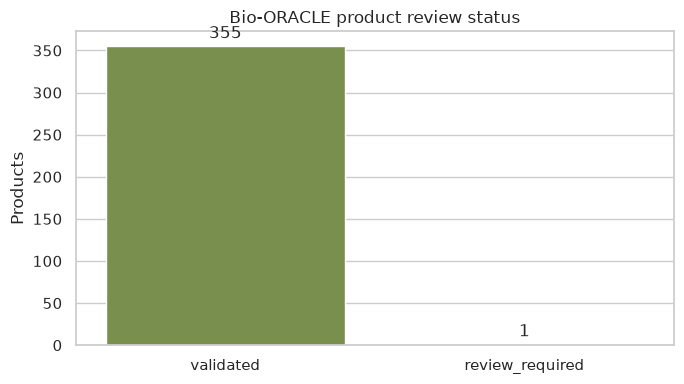

In [3]:
disposition_order = ["validated", "review_required"]
disposition_counts = (
    pd.Series([item["disposition"] for item in products])
    .value_counts()
    .reindex(disposition_order, fill_value=0)
    .rename_axis("Disposition")
    .reset_index(name="Products")
)

fig, ax = plt.subplots(figsize=(7, 4))
sns.barplot(
    data=disposition_counts,
    x="Disposition",
    y="Products",
    color="#7C9A43",
    ax=ax,
)
ax.set(title="Bio-ORACLE product review status", xlabel="", ylabel="Products")
ax.bar_label(ax.containers[0], fmt="%.0f", padding=3)
fig.tight_layout()
plt.show()


### Review the saved scientific finding

This cell reads the existing JSON summary; it does not rescan NetCDF arrays. The actual point, 3 x 3 neighborhood, and terrain checks are documented in the cleaning record.

In [4]:
review_product = next(
    item for item in summary["files"]
    if item["dataset_id"] == "kdpar_mean_baseline_2000_2020_depthsurf"
)
variable = next(item for item in review_product["variables"] if item["name"] == "kdpar_mean_range")
location = variable["marine_domain_missing_locations"][0]
slices = variable["per_time_slice"]
mask = next(
    issue["details"] for issue in summary["global_issues"]
    if issue["code"] == "marine_mask_unresolved"
)

assert variable["attributes"]["_FillValue"] == -9999.9
assert variable["attributes"]["units"] == "m-1"
assert location["time"] == "2000-01-01T00:00:00Z"
assert (location["latitude_index"], location["longitude_index"]) == (119, 83)
assert slices[0]["valid_finite_elements"] == 24502
assert slices[1]["valid_finite_elements"] == 24503
assert mask["candidate_nonfill_cell_count"] == 24503
assert mask["value_counts"] == {"-9999.9": 4867, "1.0": 24503}

print("Review product:", review_product["dataset_id"])
print("Fill: -9999.9 m-1 at 2000, grid index (119, 83); keep it missing.")
print("Finite cells in the candidate domain: 24,502 (2000) | 24,503 (2010)")
print("Candidate domain: 24,503 non-fill cells; land/water meaning unresolved.")
print("See the cleaning record for the observed 2010 value and 3 x 3 neighborhood.")


Review product: kdpar_mean_baseline_2000_2020_depthsurf
Fill: -9999.9 m-1 at 2000, grid index (119, 83); keep it missing.
Finite cells in the candidate domain: 24,502 (2000) | 24,503 (2010)
Candidate domain: 24,503 non-fill cells; land/water meaning unresolved.
See the cleaning record for the observed 2010 value and 3 x 3 neighborhood.


## 5. Interpretation and next stage

The flagged value matches the declared fill value. The 2010 value and surrounding cells provide no justified replacement, so keep it missing.

The 24,503-cell non-fill pattern matches bathymetry and continuous environmental layers. However, neither the NetCDF attributes nor the reviewed publisher metadata define whether `landmass = 1.0` means land or water. Treat it only as an empirical candidate domain, not an authoritative marine mask.

Spatial integration still needs a layer subset, extraction mask, nodata and coastal-cell rules, grid alignment, and baseline time-window matching. See the [cleaning record](../../docs/records/2026-10-11-bio-oracle-cleaning.md) for detailed evidence.

## 6. Read-only checks and references

The Code cells read the saved reports and local files only. They make no network requests and write no dataset files. They do not repeat raw intake, the full array scan or the targeted scientific audit.

To force the complete array scan again from the repository root, run `python src/data_preparation/07_clean_bio_oracle_layers.py --force-full-scan`. The default run can reuse saved array diagnostics after rechecking its fingerprints and source/output hashes. See the cleaning record for the full run history and limitations.

The saved-report checks use the existing project environment; the chart uses the project-pinned pandas, Matplotlib and Seaborn packages. No package or environment changes were made for this notebook update, and no automated test suite was run.

- [Staging script](../../src/data_preparation/06_stage_bio_oracle_layers.py)
- [Cleaner](../../src/data_preparation/07_clean_bio_oracle_layers.py)
- [Bio-ORACLE source record](../../docs/records/2026-10-09-source-bio-oracle-sri-lanka-catalog.md)
- [Bio-ORACLE cleaning record](../../docs/records/2026-10-11-bio-oracle-cleaning.md)
- [D-049 interim retention decision](../../docs/records/2026-10-11-decision-interim-one-current-dataset.md)
- [Data storage conventions](../../docs/data/data-storage-and-provenance.md)
- [Publisher terrain metadata](https://erddap.bio-oracle.org/erddap/info/terrain_characteristics/index.html)